# Домашнє завдання: Побудова класифікатора сентименту на основі набору даних Tweet Sentiment Extraction

**Мета:** Провести аналіз набору даних, виконати векторизацію текстових даних за допомогою методів bag-of-words та TF-IDF, порівняти їх, побудувати класифікатор та провести аналіз помилок.

**Набір даних:**
Дані беремо з цього змагання на Kaggle: https://www.kaggle.com/competitions/tweet-sentiment-extraction/data?select=train.csv


Якщо не вдається завантажиит з Kaggle, ось тут можна - https://drive.google.com/file/d/1kfu5zCRsDHxoBZigBlGIcCieKlws02HT/view?usp=sharing

Оригінальне змагання має дещо іншу задачу, але ми будемо поки будувати саме класифікатор.

Увага! В цьому наборі завдань для простоти експериментів ми будемо спочатку робити векторизацію на всьому наборі даних, а потім розбивку на train i test. В робочих проєктах ми теж можемо використати цей підхід для швидшої побудови PoC (proof of concept). Але фінальне рішення, яке ми будемо деплоїти - треба проводити за правилом - спочатку розбивка на трейн і тест, потім пишемо обробку для трейну, навчаємо векторизатори. І потім використовуємо готові векторизатори для тесту і всіх даних на етапі передбачення (інференсу).

### Завдання 1. Завантаження та ознайомлення з набором даних

- Завантажте набір даних `train.csv` з посилання та ознайомтеся з його структурою.
- Виведіть перші 5 рядків та основну статистику: кількість записів, типи колонок, кількість пропущених значень.
- Видаліть записи, в яких є пропущені значення.



In [127]:
import matplotlib.pyplot as plt
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from ml_homework.classification import (
    compare_multiclass_models,
    multiclass_coefficients,
)
from ml_homework.paths import RAW_DATA_DIR
from ml_homework.text import (
    SENTIMENT_NEGATION_WORDS,
    count_vocabulary_coverage,
    ensure_nltk_resources,
    filter_sentiment_tokens,
    fit_count_vectorizer,
)

In [128]:
VOCABULARY_SIZES = (1_000, 3_000, 5_000, 10_000)
MAX_VOCABULARY_FEATURES = 5_000
TEST_SIZE = 0.2
RANDOM_STATE = 42

LOGISTIC_REGRESSION_PARAMS = {
    "solver": "lbfgs",
    "max_iter": 1_000,
    "random_state": RANDOM_STATE,
}
DECISION_TREE_PARAMS = {
    "max_depth": 20,
    "min_samples_leaf": 5,
    "random_state": RANDOM_STATE,
}
XGBOOST_PARAMS = {
    "n_estimators": 150,
    "max_depth": 4,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "multi:softprob",
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

In [129]:
df = pd.read_csv(RAW_DATA_DIR / "tweet_sentiment_train.csv.zip").copy()

In [130]:
df.head()

,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


In [131]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27481 entries, 0 to 27480
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   textID         27481 non-null  str  
 1   text           27480 non-null  str  
 2   selected_text  27480 non-null  str  
 3   sentiment      27481 non-null  str  
dtypes: str(4)
memory usage: 4.1 MB


In [132]:
df.shape

(27481, 4)

In [133]:
df.dtypes

textID           str
text             str
selected_text    str
sentiment        str
dtype: object

In [134]:
df.isnull().sum()

textID           0
text             1
selected_text    1
sentiment        0
dtype: int64

In [135]:
df = df.dropna().reset_index(drop=True)

In [136]:
df.isnull().sum()

textID           0
text             0
selected_text    0
sentiment        0
dtype: int64

### Завдання 2. Exploratory Data Analysis

- Проведіть аналіз кількості класів та розподілу міток. Класи знаходяться в колонці `sentiment`.
- Візуалізуйте розподіл довжин текстів в символах та зробіть висновок про довжини постів: якої довжини постів найбільше, що бачите з розподілу?



In [137]:
sentiment_counts = df["sentiment"].value_counts()
sentiment_counts

sentiment
neutral     11117
positive     8582
negative     7781
Name: count, dtype: int64

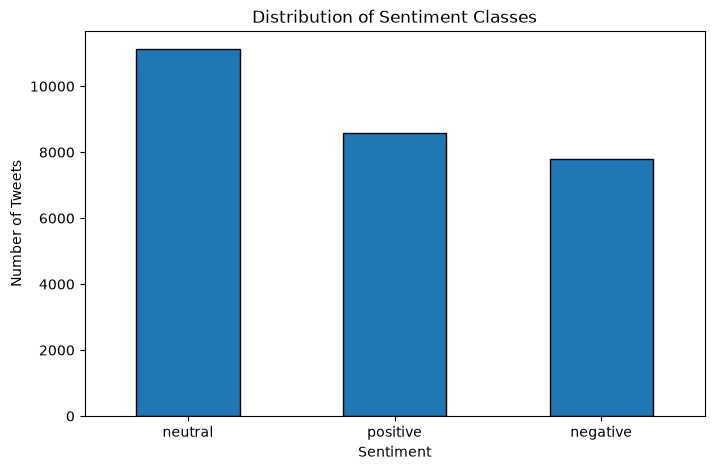

In [138]:
sentiment_counts.plot(kind="bar", figsize=(8, 5), edgecolor="black")

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.show()

In [139]:
df["text_length"] = df["text"].str.len()

df[["text", "text_length"]].sort_values(by="text_length", ascending=False).head(15)

,text,text_length
3137,Is so freaking bored on the bus. Hate being po...,141
27317,just saw an advert for ATTICS TO EDEN on tv o...,141
13895,Feeling madly sorry for myself... - ï¿½Iï¿½M S...,140
2581,TODAy SUCKs - kisskass19: ï¿½you and katey bro...,139
27066,"Jamie @ Sean Cody, up for some angry ****?: Ja...",139
16850,"4 novos followers http://migre.me/SfN Sorry, t...",139
12455,Have ordered the cuuutest invitations for my n...,139
1750,F.Y.I. a lot of you people that are following ...,138
5645,wow! party! my new life! it is awesome! no mor...,138
20119,Left 'Up' due to out-of-focus projection. Ho...,138


In [140]:
df["text_length"].value_counts()

text_length
41     308
46     301
48     301
42     298
45     295
      ... 
4        8
3        5
139      4
141      2
140      1
Name: count, Length: 139, dtype: int64

In [141]:
df.groupby("sentiment")["text_length"].agg(["mean", "median", "min", "max"])

,mean,median,min,max
sentiment,,,,
negative,70.488112,66.0,5,141
neutral,65.206800,59.0,3,141
positive,70.419133,67.0,5,138


<Axes: >

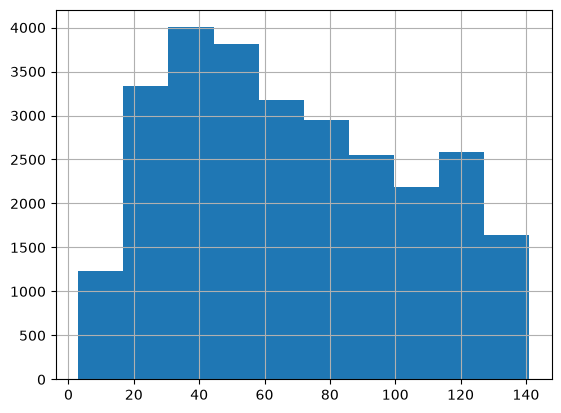

In [142]:
df["text_length"].hist()

In [143]:
df["text_length"].describe()

count    27480.000000
mean        68.330022
std         35.603870
min          3.000000
25%         39.000000
50%         64.000000
75%         97.000000
max        141.000000
Name: text_length, dtype: float64

<Axes: >

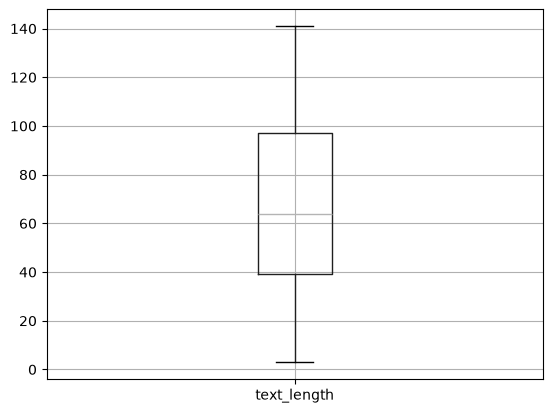

In [144]:
df.boxplot(column="text_length")

У датасеті найбільше нейтральних твітів - 11 117, позитивних - 8 582, негативних - 7 781. Сильного дисбалансу класів немає.

Більшість постів мають довжину 20–80 символів, найчастіше - 30–50. Нейтральні пости в середньому коротші (65 символів), ніж позитивні та негативні (близько 70 символів).

### Завдання 3. Попередня обробка текстових даних та векторизація з bag of words


Наша задача тут отримати вектори методом bag of words колонки `text`, виконавши попередню обробку тексту.
Попередня обробка має включати
- видалення stopwords необхідної мови
- токенізація (розбиття текстів на фрагменти по 1 слову)
- стеммінг слів зі `SnowballStemmer`.
- самостійно задайте кількість слів в словнику для `sklearn.feature_extraction.text.CountVectorizer`. Можливо для цього доведеться виконати додатковий аналіз.

Ви також можете додати сюди додаткові методи очистки текстів, наприклад, видалення деяких символів чи груп символів, якщо в процесі роботи побачите, що хочете щось видалити.

Напишіть код аби виконати це завдання. Перед цим рекомендую детально ознайомитись з тим, що робить обʼєкт `sklearn.feature_extraction.text.CountVectorizer` за замовченням.

Це завдання можна виконати двома способами - один - максимально подібно до того, як ми це робили в лекції, другий - дещо інакше перегрупувавши етапи обробки тексту.




In [145]:
ensure_nltk_resources()

In [146]:
def tokenize_text(text):
    return word_tokenize(text.lower())

In [147]:
df["tokens"] = df["text"].apply(tokenize_text)

In [148]:
df["tokens"].head()

0    [i, `, d, have, responded, ,, if, i, were, going]
1    [sooo, sad, i, will, miss, you, here, in, san,...
2                    [my, boss, is, bullying, me, ...]
3               [what, interview, !, leave, me, alone]
4    [sons, of, *, *, *, *, ,, why, couldn, `, t, t...
Name: tokens, dtype: object

In [149]:
english_stopwords = set(stopwords.words("english")) - SENTIMENT_NEGATION_WORDS

In [150]:
", ".join(sorted(english_stopwords))

"a, about, above, after, again, against, ain, all, am, an, and, any, are, aren, aren't, as, at, be, because, been, before, being, below, between, both, but, by, can, couldn, couldn't, d, did, didn, didn't, do, does, doesn, doesn't, doing, don, don't, down, during, each, few, for, from, further, had, hadn, hadn't, has, hasn, hasn't, have, haven, haven't, having, he, he'd, he'll, he's, her, here, hers, herself, him, himself, his, how, i, i'd, i'll, i'm, i've, if, in, into, is, isn, isn't, it, it'd, it'll, it's, its, itself, just, ll, m, ma, me, mightn, mightn't, more, most, mustn, mustn't, my, myself, needn, needn't, now, o, of, off, on, once, only, or, other, our, ours, ourselves, out, over, own, re, s, same, shan, shan't, she, she'd, she'll, she's, should, should've, shouldn, shouldn't, so, some, such, t, than, that, that'll, the, their, theirs, them, themselves, then, there, these, they, they'd, they'll, they're, they've, this, those, through, to, too, under, until, up, ve, very, was,

Фільтруємо пунктуацію, односимвольні токени й stopwords. Скорочене заперечення `n't` перетворюємо на `not`: воно важливе для визначення тональності. Логіка зібрана в `filter_sentiment_tokens`. 

In [151]:
df["tokens_without_stopwords"] = df["tokens"].apply(
    filter_sentiment_tokens, stop_words=english_stopwords
)

In [152]:
df["tokens_without_stopwords"].head()

0                        [responded, going]
1             [sooo, sad, miss, san, diego]
2                          [boss, bullying]
3                 [interview, leave, alone]
4    [sons, put, releases, already, bought]
Name: tokens_without_stopwords, dtype: object

In [153]:
stemmer = SnowballStemmer("english")

In [154]:
def stem_tokens(tokens):
    return [stemmer.stem(token) for token in tokens]

In [155]:
df["stemmed_text"] = df["tokens_without_stopwords"].apply(stem_tokens)

In [156]:
df["stemmed_text"].head()

0                          [respond, go]
1          [sooo, sad, miss, san, diego]
2                          [boss, bulli]
3                [interview, leav, alon]
4    [son, put, releas, alreadi, bought]
Name: stemmed_text, dtype: object

In [157]:
df["processed_text"] = df["stemmed_text"].apply(" ".join)

X = df["processed_text"]
y = df["sentiment"]

In [158]:
coverage_df = count_vocabulary_coverage(X, VOCABULARY_SIZES)

In [159]:
coverage_df.round(2)

,max_features,vocabulary,coverage_pct
0,1000,1000,74.40
1,3000,3000,87.32
2,5000,5000,91.58
3,10000,10000,95.87


`analyzer=str.split` передає векторизатору вже очищені та стемінговані токени без повторної токенізації. Для Bag-of-Words обрано `max_features=5000`: цей словник покриває 91,58% появ слів у корпусі, а 10000 ознак - 95,87%. У завданні 4 словник для моделі навчається заново лише на тренувальних текстах. Покриття та вибір розміру словника на всьому корпусі тут є навчальним спрощенням з умови завдання; для строгої оцінки `max_features` слід добирати лише на train (наприклад, крос-валідацією).

In [160]:
vectorizer = CountVectorizer(max_features=MAX_VOCABULARY_FEATURES, analyzer=str.split)
X_bow = vectorizer.fit_transform(X)

In [161]:
vectorizer.get_feature_names_out()[:30]

array(['aaaah', 'aaah', 'aaahhh', 'aah', 'aaron', 'ab', 'abandon', 'abbi',
       'abil', 'abit', 'abl', 'absolut', 'abt', 'abus', 'ac', 'academ',
       'academi', 'accept', 'access', 'accid', 'accident', 'accomplish',
       'accord', 'account', 'acct', 'ace', 'ach', 'achiev', 'acid', 'ack'],
      dtype=object)

In [162]:
X_bow.shape

(27480, 5000)

In [163]:
word_counts = pd.Series(X_bow.sum(axis=0).A1, index=vectorizer.get_feature_names_out())

word_counts.sort_values(ascending=False).head(20)

day      2417
go       2375
get      1913
not      1908
good     1592
work     1522
love     1480
like     1458
no       1372
got      1258
http     1243
today    1150
time     1096
one      1070
lol      1016
happi    1012
want      984
thank     980
know      978
miss      965
dtype: int64

### Завдання 4. Побудова класифікатора

- Розділіть індекси даних на навчальний та тестовий набори в обраному співвівдношенні. Використовуючи отримані індекси сфомуйте набори для тренування класифікатора `X_train_bow, X_test_bow, y_train, y_test`.
- Навчіть класифікатор (наприклад, Logistic Regression, Decision Tree або один з алгоритмів бустингу) на даних, векторизованих методом bag-of-words. Спробуйте кілька моделей і оберіть найбільш точну :)
- Виведіть інформацію, яка дає можливість оцінити якість класифікації.
- Оцініть якість фінальної класифікації: вона хороша чи не дуже?



In [164]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

In [165]:
vectorizer, X_train_bow, X_test_bow = fit_count_vectorizer(
    X_train, X_test, max_features=MAX_VOCABULARY_FEATURES
)

In [166]:
print("Train:", X_train_bow.shape)
print("Test:", X_test_bow.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Train: (21984, 5000)
Test: (5496, 5000)
y_train: (21984,)
y_test: (5496,)


In [167]:
model = LogisticRegression(**LOGISTIC_REGRESSION_PARAMS)

model.fit(X_train_bow, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [168]:
y_pred = model.predict(X_test_bow)

In [169]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6925036390101892
              precision    recall  f1-score   support

    negative       0.71      0.64      0.67      1556
     neutral       0.63      0.72      0.67      2223
    positive       0.78      0.71      0.74      1717

    accuracy                           0.69      5496
   macro avg       0.71      0.69      0.69      5496
weighted avg       0.70      0.69      0.69      5496



In [170]:
y_proba = model.predict_proba(X_test_bow)

roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8401467050899764


In [171]:
tree_model = DecisionTreeClassifier(**DECISION_TREE_PARAMS)

tree_model.fit(X_train_bow, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [172]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)

['negative' 'neutral' 'positive']


In [173]:
xgb_model = XGBClassifier(**XGBOOST_PARAMS)

xgb_model.fit(X_train_bow, y_train_encoded)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

In [174]:
models_to_compare = [
    ("Logistic Regression", model, X_test_bow, None),
    ("Decision Tree", tree_model, X_test_bow, None),
    ("XGBoost", xgb_model, X_test_bow, label_encoder),
]

In [175]:
results_df = compare_multiclass_models(
    models_to_compare, y_test, labels=label_encoder.classes_
)
results_df.sort_values(by="F1-macro", ascending=False).round(4)

,Model,Accuracy,F1-macro,ROC-AUC
0,Logistic Regression,0.6925,0.6945,0.8401
2,XGBoost,0.6712,0.6639,0.8237
1,Decision Tree,0.6272,0.6057,0.7401


In [176]:
y_proba = xgb_model.predict_proba(X_test_bow)

auc_per_class = roc_auc_score(y_test_encoded, y_proba, multi_class="ovr", average=None)

pd.Series(auc_per_class, index=label_encoder.classes_)

negative    0.839330
neutral     0.763580
positive    0.868256
dtype: float64

Було порівняно Logistic Regression, Decision Tree та XGBoost на однакових Bag-of-Words ознаках і тестових записах. Найкращий macro-F1 показала Logistic Regression: accuracy = 0,6925, macro-F1 = 0,6945, ROC-AUC = 0,8401. Для подальшого аналізу вирішила обрати цю модель.

### Завдання 5. Аналіз впливовості слів в отриманого класифікатора

- Для обраної вами моделі проведіть аналіз важливості слів (ознак): які слова (токени) найбільше впливають для визначення сентименту? Чи це логічно на ваш погляд, що саме ці символи впливають найбільше/найменще?


In [177]:
feature_importance = multiclass_coefficients(model, vectorizer.get_feature_names_out())
feature_importance.head()

,negative,neutral,positive
aaaah,0.306209,-0.138540,-0.167669
aah,0.514414,-0.589569,0.075155
aaron,-0.184110,0.288851,-0.104742
ab,-0.080122,-0.091264,0.171387
abandon,0.209058,0.221453,-0.430511


In [178]:
feature_importance["positive"].nlargest(10)

awesom       2.623588
cute         2.544351
thank        2.487997
love         2.399170
glad         2.310566
amaz         2.276044
enjoy        2.132106
nice         2.096372
excit        2.079908
congratul    2.034953
Name: positive, dtype: float64

In [179]:
feature_importance["positive"].nsmallest(10)

shame     -2.585174
sorri     -2.572252
sad       -2.508452
suck      -2.481632
bore      -2.216513
horribl   -2.019560
hate      -1.981565
jealous   -1.945715
miss      -1.927793
tire      -1.881275
Name: positive, dtype: float64

In [180]:
feature_importance["negative"].nlargest(10)

sad        2.679931
suck       2.567658
sorri      2.426062
bore       2.355492
hate       2.279251
fail       2.168063
miss       2.135100
terribl    2.082590
stupid     2.074325
worst      2.065451
Name: negative, dtype: float64

In [181]:
feature_importance["negative"].nsmallest(10)

awesom   -2.426258
glad     -2.313024
love     -2.120633
beauti   -1.988395
thank    -1.978505
cute     -1.823780
welcom   -1.708445
enjoy    -1.641956
amaz     -1.593734
nice     -1.514557
Name: negative, dtype: float64

In [182]:
feature_importance["neutral"].nlargest(10)

indoor         1.572755
otherwis       1.339552
oooo           1.256916
parvo          1.215394
jst            1.155966
hamilton       1.137517
starwarsday    1.133679
colorado       1.102535
twhirl         1.091579
hummmmm        1.086264
Name: neutral, dtype: float64

In [183]:
feature_importance["neutral"].nsmallest(10)

forum       -1.385737
congratul   -1.354900
wtf         -1.348623
incred      -1.326350
thrill      -1.254262
impati      -1.214742
nut         -1.171638
truli       -1.162830
proud       -1.150884
product     -1.145418
Name: neutral, dtype: float64

Аналіз коефіцієнтів Logistic Regression показав, що модель логічно розпізнає емоційно забарвлені слова. Для позитивного класу найбільші додатні коефіцієнти мають `awesom`, `love`, `thank`, а найбільші від'ємні - `shame`, `sad`, `suck`. Для негативного класу ситуація протилежна: `sad`, `hate`, `suck` підвищують його оцінку, а `love`, `glad`, `awesom` - знижують.

Для нейтрального класу найвпливовіші ознаки менш очевидні й можуть відображати особливості датасету. Загалом результати логічні, хоча модель враховує статистичні зв'язки слів із класами, а не їхній контекст чи справжнє значення.

### Завдання 6. Векторизація текстів з допомогою TF-IDF. Тренування класифікатора, аналіз точності і впливовості слів.

- Проведіть векторизацію текстів з векторизатором TfidfVectorizer. Реалізуйте векторизацію так, аби препроцесинг включав всі ті самі кроки, що і в випадку використання векторизації Bag of Words.

- Натренуйте той самий класифікатор на TF-IDF векторах, виконавши розбивку набору даних на train, test так, аби в трейні були всі ті самі записи, що і були в попередньому завданні (це важливо для порівняння результатів).

- Проаналізуйте якість класифікації вивівши потрібні для цього метрики. Чи стала якість класифікації кращою?

- Які токени найбільше впливають на результат при тренуваннні класифікатора з TF-IDF векторами? Порівняйте з найважливішими токенами при Bag of Words векторизації. Яку векторизацію ви б обрали для фінальної імплементації рішення? Обґрунтуйте свій вибір.



In [184]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=MAX_VOCABULARY_FEATURES, analyzer=str.split
)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

tfidf_model = LogisticRegression(**LOGISTIC_REGRESSION_PARAMS)
tfidf_model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [185]:
tfidf_pred = tfidf_model.predict(X_test_tfidf)

vectorizers_to_compare = [
    ("BoW", model, X_test_bow, None),
    ("TF-IDF", tfidf_model, X_test_tfidf, None),
]
comparison_metrics = (
    compare_multiclass_models(
        vectorizers_to_compare, y_test, labels=label_encoder.classes_
    )
    .set_index("Model")
    .rename_axis("Векторизація")
)

print(comparison_metrics.round(4))

              Accuracy  F1-macro  ROC-AUC
Векторизація                             
BoW             0.6925    0.6945   0.8401
TF-IDF          0.6909    0.6925   0.8516


In [186]:
print("\nTF-IDF classification report:")
print(classification_report(y_test, tfidf_pred))


TF-IDF classification report:
              precision    recall  f1-score   support

    negative       0.73      0.62      0.67      1556
     neutral       0.62      0.74      0.68      2223
    positive       0.78      0.69      0.73      1717

    accuracy                           0.69      5496
   macro avg       0.71      0.68      0.69      5496
weighted avg       0.70      0.69      0.69      5496



In [187]:
tfidf_importance = multiclass_coefficients(
    tfidf_model, tfidf_vectorizer.get_feature_names_out()
)

top_tokens = {}
for sentiment in model.classes_:
    top_tokens[f"BoW {sentiment}"] = feature_importance[sentiment].nlargest(10).index
    top_tokens[f"TF-IDF {sentiment}"] = tfidf_importance[sentiment].nlargest(10).index

pd.DataFrame(top_tokens)

,BoW negative,TF-IDF negative,BoW neutral,TF-IDF neutral,BoW positive,TF-IDF positive
0,sad,sad,indoor,indoor,awesom,love
1,suck,miss,otherwis,guitar,cute,thank
2,sorri,sorri,oooo,except,thank,awesom
3,bore,suck,parvo,knock,love,happi
4,hate,hate,jst,starwarsday,glad,good
5,fail,bore,hamilton,otherwis,amaz,great
6,miss,fail,starwarsday,jst,enjoy,nice
7,terribl,hurt,colorado,differ,nice,hope
8,stupid,stupid,twhirl,goin,excit,amaz
9,worst,poor,hummmmm,sent,congratul,enjoy


На однаковому тестовому наборі BoW має трохи вищі accuracy (0,6925 проти 0,6909) та macro-F1 (0,6945 проти 0,6925), а TF-IDF - вищий ROC-AUC (0,8516 проти 0,8401). Найвпливовіші позитивні й негативні токени переважно збігаються між підходами, хоча їхній порядок змінюється. Для поточного завдання класифікації за macro-F1 обираю BoW.

### Завдання 7. Аналіз помилок класифікації з векторизацією TF-IDF.

- Проаналізуйте, на яких екземплярах помиляється класифікатор при векторизації TF-IDF.
- На основі аналізу запропонуйте 3 шляхи поліпшення якості класифікації.

In [188]:
test_results = df.loc[X_test.index, ["text", "processed_text", "sentiment"]].assign(
    prediction=tfidf_pred,
    confidence=tfidf_model.predict_proba(X_test_tfidf).max(axis=1),
)
mistakes = test_results[test_results["sentiment"] != test_results["prediction"]]

print("Помилки на тестовій вибірці:", len(mistakes), "із", len(test_results))
print(pd.crosstab(test_results["sentiment"], test_results["prediction"]))
mistakes.nlargest(10, "confidence")

Помилки на тестовій вибірці: 1699 із 5496
prediction  negative  neutral  positive
sentiment                              
negative         962      533        61
neutral          300     1651       272
positive          60      473      1184


,text,processed_text,sentiment,prediction,confidence
982,I sorry,sorri,positive,negative,0.985439
8129,Well that just sucks. Good way to make me feel...,well suck good way make feel bad,neutral,negative,0.969360
12444,is feeling Fab today and missing my boo,feel fab today miss boo,neutral,negative,0.964481
3323,Should I say goodnight or good morning?,say goodnight good morn,neutral,positive,0.961265
753,awwww..I love him! His car was soooo CUTE toni...,awwww love car soooo cute tonight love carl ol...,neutral,positive,0.958827
7396,_Cullen8 i hate the rain *laughs*. thanks *smi...,hate rain laugh thank smile miss load couldnt ...,neutral,negative,0.957533
16288,if you are a cute guy add/follow me i`ll do t...,cute guy,neutral,positive,0.955706
20853,funny u havent showed me any love yet at all,funni havent show love yet,neutral,positive,0.954414
13171,don`t know what to do today. amazing weather ...,know today amaz weather sit great,neutral,positive,0.952258
22874,"yes the new one, I adore both though who doe...",yes new one ador though love vincent,neutral,positive,0.951314


На тестовій вибірці TF-IDF модель помилилася у 1 699 із 5 496 випадків. Найчастіше вона плутає полярні висловлювання з нейтральними: 533 негативні та 473 позитивні тексти передбачені як нейтральні. Також 300 нейтральних текстів передбачені як негативні, а 272 — як позитивні. Серед помилок із високою впевненістю є неоднозначні короткі повідомлення та тексти зі словами різної тональності; наприклад, `I sorry` має мітку positive, але модель передбачає negative. Це привід перевірити розмітку, а не автоматично змінювати тестові мітки.

Три шляхи поліпшення:

1. Додати словесні та символьні n-грами, щоб модель бачила короткі фрази, заперечення, емотикони й нестандартне написання слів у твітах.
2. Підібрати `C` для Logistic Regression та параметри TF-IDF (`ngram_range`, `min_df`, `sublinear_tf`) крос-валідацією лише на навчальній вибірці, орієнтуючись на macro-F1. Тестову вибірку залишити для фінальної перевірки.
3. Переглянути неоднозначні й суперечливо розмічені приклади в навчальних даних та за потреби поліпшити їхню розмітку або додати подібні приклади до навчання. Тестові мітки не змінювати.

І на фінал кернел для натхнення і ознайомлення з рішенням оригінальної задачі. Багато цікавих візуалізацій і аналізу є тут, а також тут розвʼязується саме проблема named entitty recognition і можна ознайомитись як це робиться - вона дещо складніша по своїй суті ніж класифікація, подумайте, чому:

https://www.kaggle.com/code/tanulsingh077/twitter-sentiment-extaction-analysis-eda-and-model